DATASET
   Time     Value
0     0  0.024836
1     1  0.087897
2     2  0.220874
3     3  0.356079
4     4  0.356354

SEQUENCE DATA
X Shape: (480, 20, 1)
Y Shape: (480, 1)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.1416 - val_loss: 0.0282
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0069 - val_loss: 0.0061
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0034 - val_loss: 0.0026
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0025 - val_loss: 0.0022
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0022 - val_loss: 0.0018
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0020 - val_loss: 0.0018
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0019 - val_loss: 0.0016
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0018 - val_loss: 0.0015
Epoch 9/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0017 - val_loss: 0.0014
Epoch 10/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0016 - val_loss: 0.0014
Epoch 11/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0015 - val_loss: 0.0013
Epoch 12/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0015 - val

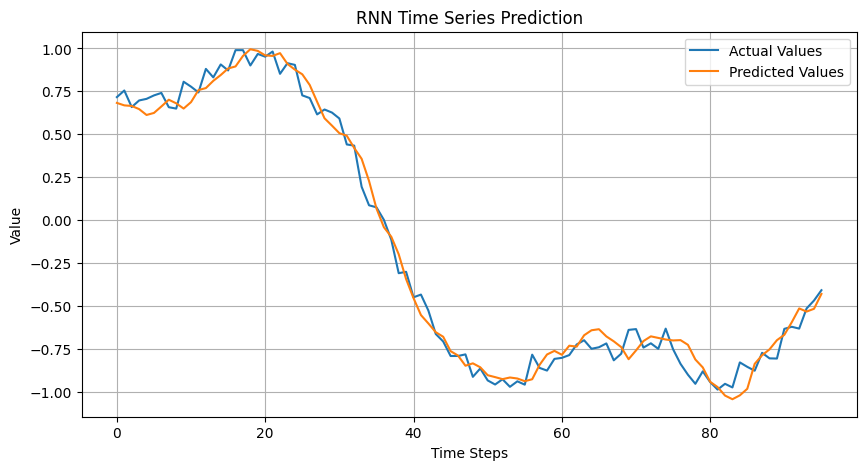

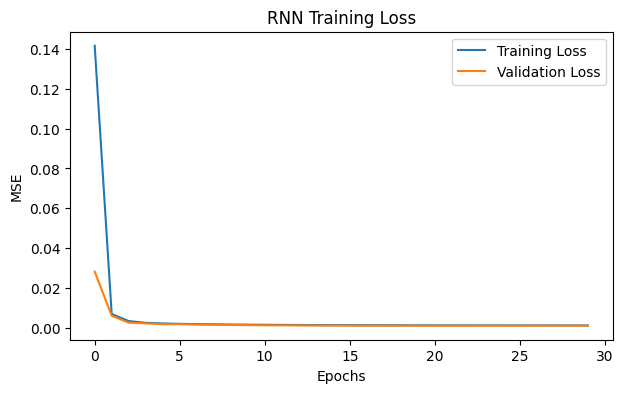

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler

# 1. Generate sequential time-series data
np.random.seed(42)

time = np.arange(500)

values = (
    np.sin(0.05 * time)
    + 0.3 * np.sin(0.15 * time)
    + np.random.normal(0, 0.05, 500)
)

# 2. Create DataFrame
data = pd.DataFrame({
    "Time": time,
    "Value": values
})

print("DATASET")
print(data.head())

# 3. Normalize data
scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(
    data[["Value"]]
)

# 4. Create sequential dataset
def create_sequences(data, window_size):

    X, y = [], []

    for i in range(len(data) - window_size):

        X.append(data[i:i + window_size])

        y.append(data[i + window_size])

    return np.array(X), np.array(y)

window_size = 20

X, y = create_sequences(
    scaled_data,
    window_size
)

print("\nSEQUENCE DATA")
print("X Shape:", X.shape)
print("Y Shape:", y.shape)

# 5. Split dataset
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

# 6. Build RNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(window_size, 1)),

    tf.keras.layers.SimpleRNN(
        50,
        activation="tanh"
    ),

    tf.keras.layers.Dense(1)
])

# 7. Compile model
model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

# 8. Train model
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

# 9. Predict future values
predictions = model.predict(
    X_test,
    verbose=0
)

# Convert values to original scale
predictions = scaler.inverse_transform(predictions)

actual = scaler.inverse_transform(y_test)

print("\nPREDICTED VALUES")
print(predictions[:10])

# 10. Plot actual and predicted values
plt.figure(figsize=(10, 5))

plt.plot(
    actual,
    label="Actual Values"
)

plt.plot(
    predictions,
    label="Predicted Values"
)

plt.xlabel("Time Steps")
plt.ylabel("Value")

plt.title("RNN Time Series Prediction")

plt.legend()
plt.grid()
plt.show()

# 11. Plot training loss
plt.figure(figsize=(7, 4))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("RNN Training Loss")

plt.xlabel("Epochs")
plt.ylabel("MSE")

plt.legend()
plt.show()